In [34]:
import os
import torch
import torchvision
from torch.utils.data import random_split
import torchvision.models as models
import torch.nn as nn
import torch.nn.functional as F
from torchvision.datasets import ImageFolder
import torchvision.transforms as transforms
import ssl

In [2]:
data_dir = '/Users/local/Projects/vooclass/data/Garbage classification/Garbage classification'
classes = os.listdir(data_dir)
print(classes)

['paper', 'metal', 'cardboard', 'trash', 'glass', 'plastic']


In [5]:
transformations = transforms.Compose(
    [
        transforms.Resize((256, 256)),
        transforms.ToTensor()
    ]
)
dataset = ImageFolder(data_dir, transform=transformations)

In [6]:
dataset

Dataset ImageFolder
    Number of datapoints: 2527
    Root location: /Users/local/Projects/vooclass/data/Garbage classification/Garbage classification
    StandardTransform
Transform: Compose(
               Resize(size=(256, 256), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )

In [7]:
len(dataset)

2527

In [8]:
dataset[0]

(tensor([[[0.9451, 0.9490, 0.9529,  ..., 0.8431, 0.8392, 0.8471],
          [0.9529, 0.9569, 0.9569,  ..., 0.8510, 0.8471, 0.8431],
          [0.9608, 0.9647, 0.9608,  ..., 0.8549, 0.8549, 0.8431],
          ...,
          [0.7412, 0.7373, 0.7176,  ..., 0.4431, 0.4510, 0.4549],
          [0.7333, 0.7333, 0.7255,  ..., 0.4471, 0.4510, 0.4510],
          [0.7333, 0.7255, 0.7176,  ..., 0.4471, 0.4471, 0.4510]],
 
         [[0.7882, 0.7922, 0.7961,  ..., 0.6706, 0.6667, 0.6745],
          [0.7961, 0.8000, 0.8000,  ..., 0.6784, 0.6745, 0.6706],
          [0.8039, 0.8078, 0.8039,  ..., 0.6824, 0.6824, 0.6706],
          ...,
          [0.5882, 0.5804, 0.5725,  ..., 0.3451, 0.3529, 0.3569],
          [0.5804, 0.5804, 0.5765,  ..., 0.3490, 0.3529, 0.3529],
          [0.5765, 0.5686, 0.5686,  ..., 0.3490, 0.3490, 0.3529]],
 
         [[0.6510, 0.6549, 0.6588,  ..., 0.5569, 0.5529, 0.5608],
          [0.6588, 0.6627, 0.6627,  ..., 0.5647, 0.5608, 0.5569],
          [0.6667, 0.6706, 0.6667,  ...,

In [12]:
import matplotlib.pyplot as plt
%matplotlib inline

In [13]:
dataset[0][0].shape

torch.Size([3, 256, 256])

In [18]:
def show_sample(img, labels):
    print("Label:", dataset.classes[labels])
    img = img.permute(1, 2, 0).detach().cpu().numpy()
    # rearrange to height, width, channel, needed because matplotlib expects image data in [height, width, channel] form, change from [c, h, w] to [h, w, c]
    plt.imshow(img)
    plt.title(f"Label: {dataset.classes[labels]}")
    plt.axis("off")
    plt.show()

torch.Size([3, 256, 256])
Label: cardboard


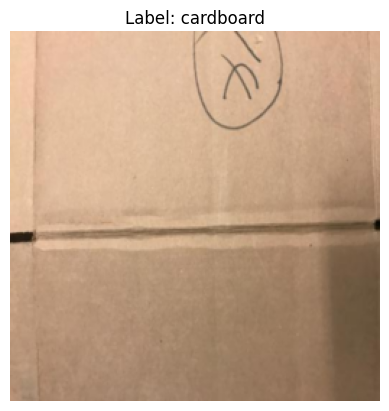

In [19]:
img,label = dataset[0]
print(img.shape)
show_sample(img,label)

In [20]:
random_seed = 42
torch.manual_seed(random_seed)

In [23]:
train_ds, val_ds, test_ds = random_split(dataset, [2000, 300, 227])
len(train_ds), len(val_ds), len(test_ds)

(2000, 300, 227)

In [24]:
from torch.utils.data.dataloader import DataLoader
batch_size = 32

In [25]:
train_dl = DataLoader(train_ds, batch_size, shuffle=True, num_workers=4, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size*2, num_workers=4, pin_memory=True)

In [26]:
from torchvision.utils import make_grid
def show_batch(dl):
    for images, labels in dl:
        fig, ax = plt.subplots(figsize=(12, 6))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.imshow(make_grid(images, nrow = 16).permute(1,2, 0))
        break

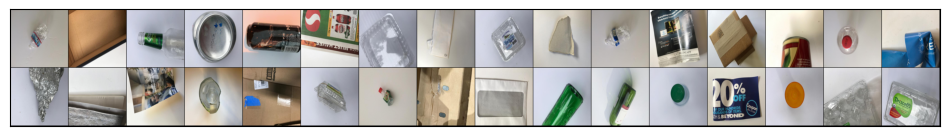

In [27]:
show_batch(train_dl)

In [28]:
def accuracy(outputs, labels):
    _, preds = torch.max(outputs, dim=1)
    return torch.tensor(torch.sum(preds == labels).item() / len(preds))

class ImageClassifier(nn.Module):
    def training_step(self, batch):
        images, labels = batch
        out = self(images)
        loss = F.cross_entropy(out, labels) #all vectors
        return loss
    
    def validation_step(self, batch):
        images, labels = batch
        out = self(images)
        loss = F.cross_entropy(out, labels)
        acc = accuracy(out, labels)
        return {'val_loss': loss.detach(), 'val_acc': acc}
    
    def validation_epoch_end(self, outputs):
        batch_losses = [x['val_loss'] for x in outputs]
        epoch_loss = torch.stack(batch_losses).mean()
        batch_accs = [x['val_acc'] for x in outputs]
        epoch_acc = torch.stack(batch_accs).mean()
        return {'val_loss': epoch_loss.item(), 'val_acc': epoch_acc.item()}
    
    def epoch_end(self, epoch, result):
        print("Epoch {}: train_loss: {:.4f}, val_acc: {:.4f}".format(
            epoch+1, result['train_loss'], result['val_loss'], result['val_acc']))

In [35]:
class ResNet(ImageClassifier):
    def __init__(self):
        super().__init__()
        self.network = models.resnet50(pretrained=False)
        num_ftrs = self.network.fc.in_features
        self.network.fc = nn.Linear(num_ftrs, len(dataset.classes))
    
    def forward(self, xb):
        return torch.sigmoid(self.network(xb))
model = ResNet()

/Users/local/Projects/vooclass/venv/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


In [36]:
model

ResNet(
  (network): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Sequential(
          (

In [37]:
def get_default_device():
    if torch.backends.mps.is_available():
        return torch.device('mps')
    else:
        return torch.device('cpu')

def to_device(data, device):
    if isinstance(data, (list, tuple)):
        return [to_device(x, device) for x in data]
    return data.to(device, non_blocking=True)

class DeviceDataLoader():
    def __init__(self, dl, device):
        self.dl = dl
        self.device = device
    
    def __iter__(self):
        for b in self.dl:
            yield to_device(b, self.device)
    
    def __len__(self):
        return len(self.dl)

In [38]:
device = get_default_device()
device

device(type='mps')

In [39]:
train_dl = DeviceDataLoader(train_ds, device)
val_dl = DeviceDataLoader(val_dl, device)
to_device(model, device)

ResNet(
  (network): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Sequential(
          (

In [47]:
@torch.no_grad()
def evaluate(model, val_loader):
    model.eval()
    outputs = [model.validation_step(batch) for batch in val_loader]
    return model.validation_epoch_end(outputs)

def fit(epochs, lr, model, train_loader, val_loader, opt_func=torch.optim.SGD):
    history = []
    optimizer = opt_func(model.parameters(), lr)
    for epoch in range(epochs):
        model.train()
        train_losses = []
        for batch in train_loader:
            loss = model.training_step(batch)
            train_losses.append(loss)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        result = evaluate(model, val_loader)
        result['train_loss'] = torch.stack(train_losses).mean().item()
        model.epoch_end(epoch, result)
        history.append(result)
    return history



In [52]:
model = to_device(ResNet(), device)
model

ResNet(
  (network): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Sequential(
          (

In [53]:
evaluate(model, val_dl)
model

ResNet(
  (network): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Sequential(
          (

In [54]:
num_epochs = 8
opt_func = torch.optim.Adam
lr = 5.5e-5
history = fit(num_epochs, lr, model, train_dl, val_dl, opt_func)

AttributeError: 'int' object has no attribute 'to'

In [55]:
def predict_image(img, model):
    xb = to_device(img.unsqueeze(0), device)
    print(xb.shape)
    yb = model(xb)
    print(yb)
    print(yb.shape)
    prob, preds = torch.max(yb, dim=1)
    return dataset.classes[preds[0].item()]

torch.Size([1, 3, 256, 256])
tensor([[0.6647, 0.3134, 0.3763, 0.5009, 0.4952, 0.4553]], device='mps:0',
       grad_fn=<SigmoidBackward0>)
torch.Size([1, 6])
Label: plastic , Predicted: cardboard


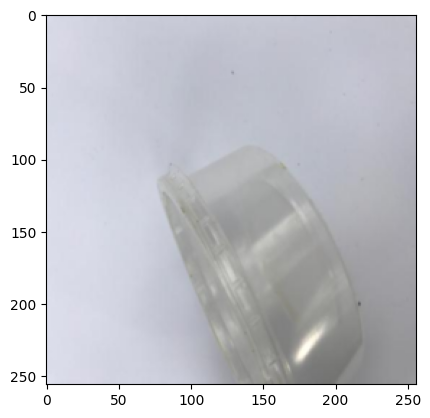

In [56]:
img, label = test_ds[17]
plt.imshow(img.permute(1, 2, 0))
print('Label:', dataset.classes[label], ', Predicted:', predict_image(img, model))